# Projekt für die Deutsche Rentenversicherung als "Proof of Work"
Im folgenden Projekt wird eine End-to-End Pipeline der Bearbeitung eines simulierten Rohdatensatzes der Deutschen Rentenversicherung für das datengeschützte Prozesscontrolling entwickelt. Die Pipeline beeinhaltet das Datenqualitätsmanagement (DQM), die explorative Datenanalyse (EDA) bis hin zur multivariaten Regressionsanalyse (OLS) und der abschließenden Modell-Auswertung. Das Thema des Projektes ist die Analyse der Antragsbearbeitungszeit und der Identifikation von Treibern höherer Bearbeitungszeiten. 

**Projektübersicht**
1. Generierung der Rohdaten
2. Bau einer Data Quality Management Pipeline (DQM)
3. Explorative Datenanalyse (EDA)
4. Regression
5. Management Summary 


# 1.0 Generierung der Rohdaten
Zunächst generieren wir einen synthetischen Rohdatensatz mit 1000 Datenpunkten, der die Variablen 'vorgangs_id', 'antragsart', 'region', 'alter_jahre', 'bearbeitungsdauer_tage' und 'status' beeinhaltet. 
Der Datensatz soll typische Fehler wie in der Realität enthalten z. B. fehlende Werte, Ausreißer bzw. unlogische Werte, Formatierungs- und Tippfehler und Duplikate. 

In [26]:
import pandas as pd
import numpy as np
import random

# Reproduzierbarkeit sicherstellen
np.random.seed(42)
random.seed(42)

n = 1000

# 1. Reale Basisdaten simulieren
data = {
    'vorgangs_id': range(10000, 10000 + n),
    'antragsart': np.random.choice(['Altersrente', 'Erwerbsminderungsrente', 'Reha-Maßnahme'], n, p=[0.6, 0.25, 0.15]),
    'region': np.random.choice(['Frankfurt', 'Kassel', 'Darmstadt', 'Gießen', 'Wiesbaden'], n),
    'alter_jahre': np.random.normal(60, 10, n).astype(int),
    'bearbeitungsdauer_tage': np.random.normal(45, 20, n).astype(int),
    'status': np.random.choice(['Bewilligt', 'Abgelehnt'], n, p=[0.75, 0.25])
}

df = pd.DataFrame(data)

# 2. DQM-Fehler gezielt einbauen

# Fehlende Werte (Missing Data)
df.loc[10:25, 'alter_jahre'] = np.nan
df.loc[100:115, 'region'] = np.nan

# Unplausible Ausreißer (Logikfehler)
df.loc[5, 'alter_jahre'] = 142
df.loc[42, 'alter_jahre'] = 12
df.loc[77, 'bearbeitungsdauer_tage'] = -14
df.loc[200, 'bearbeitungsdauer_tage'] = 1200

# Formatierungs- und Tippfehler (Text-Normalisierung)
df.loc[300:315, 'region'] = 'frankfurt'
df.loc[400:410, 'region'] = ' Darmstadt ' 

# Identische Dubletten am Ende anfügen
df = pd.concat([df, df.iloc[[10, 55, 99]]], ignore_index=True)

# Datensatz exportieren
df.to_csv('drv_antragsdaten_roh.csv', index=False)
print("Synthetischer Datensatz wurde generiert. Zeilen:", len(df))

# Vorschau
df

Synthetischer Datensatz wurde generiert. Zeilen: 1003


,vorgangs_id,antragsart,region,alter_jahre,bearbeitungsdauer_tage,status
0,10000,Altersrente,Gießen,35.0,73,Bewilligt
1,10001,Reha-Maßnahme,Darmstadt,59.0,58,Abgelehnt
2,10002,Erwerbsminderungsrente,Wiesbaden,44.0,57,Bewilligt
3,10003,Altersrente,Frankfurt,57.0,22,Bewilligt
4,10004,Altersrente,Wiesbaden,58.0,78,Bewilligt
...,...,...,...,...,...,...
998,10998,Reha-Maßnahme,Gießen,67.0,29,Abgelehnt
999,10999,Altersrente,Darmstadt,51.0,45,Bewilligt
1000,10010,Altersrente,Kassel,NaN,-11,Bewilligt
1001,10055,Reha-Maßnahme,Kassel,66.0,18,Bewilligt


In der Realität erfolgt die Datenextraktion mittels einer Datenbankabfrage. SQL bietet als Datenbanksprache bereits einige Tools, um Daten zu bereinigen und zu aggregieren. Wir simulieren diesen Schritt, indem wir die Daten an eine In-Memory-SQLite-Datenbank übergeben. Dadurch können wir verschiedene SQL-Aggregationen nutzen, um einen ersten Überblick über die Daten zu gewinnen.

In [27]:
import sqlite3

# Erstellung einer in-Memory SQLite Datenbank
conn = sqlite3.connect(':memory:')
df.to_sql('antraege', conn, index=False, if_exists='replace')

#SQL-Abrage
query = """
SELECT
    region,
    COUNT(vorgangs_id) AS anzahl_antraege,
    MIN(alter_jahre) AS min_alter,
    MAX(alter_jahre) AS max_alter,
    MIN(bearbeitungsdauer_tage) AS min_bearbeitsungsdauer,
    MAX(bearbeitungsdauer_tage) AS max_bearbeitungsdauer,
    AVG(bearbeitungsdauer_tage) AS avg_dauer
FROM antraege
GROUP BY region
ORDER BY avg_dauer DESC
;
"""

#SQL-Abfrage an ein Pandas DataFrame zurückgeben
df_sql = pd.read_sql_query(query, conn)
display(df_sql)

,region,anzahl_antraege,min_alter,max_alter,min_bearbeitsungsdauer,max_bearbeitungsdauer,avg_dauer
0,Darmstadt,11,48.0,74.0,31,79,51.272727
1,Darmstadt,164,35.0,82.0,-14,1200,49.707317
2,Wiesbaden,204,30.0,92.0,-18,110,46.132353
3,Frankfurt,186,12.0,142.0,-14,107,45.924731
4,None,16,47.0,77.0,3,81,43.812500
5,Gießen,199,31.0,84.0,-19,94,43.703518
6,Kassel,207,36.0,84.0,-11,87,43.594203
7,frankfurt,16,46.0,74.0,3,64,40.375000


Durch die SQL-Abfrage können wir folgendende Problematiken in den Rohdaten erkennen:  

**1. Inkonsistente Kategorien:** Bei den Regionen gibt es Leerzeichen- und Tipp-Fehler sowie Null-Werte.  

**2. Fehlerhafte Aggregation:** Die Durschnittswerte bei Frankfurt und Darmstadt sind fehlerhaft, da diese separat aufgeführt werden.  

**3. Ausreißer:** Auch die Altersspanne und Bearbeitungsdauer weisen Logikfehler und potentielle Ausreißer auf (z. B. Frankfurt mit min. 12 und max. 142 Jahren).  
 
**4. Null-Werte:** Wir haben Einträge ohne regionale Einordnung. 

# 2.0 Bau einer Data Quality Management Pipeline (DQM)
Dieser Abschnitt konzentriert sich auf die schrittweise Bereinigung der Daten, um die Datenqualität für die spätere Analyse abzusichern. Es werden u. a. Duplikate gelöscht, logische Wertebereiche definiert, Null-Werte ermittelt und entsprechende Zeilen gelöscht bzw. imputiert. 

## 2.1 Löschung von Duplikaten

In [28]:
# Duplikate löschen 
df = df.drop_duplicates()
df # 3 Duplikate wurden gefunden und entfernt

#Kopie erstellen
df = df.copy()
df


,vorgangs_id,antragsart,region,alter_jahre,bearbeitungsdauer_tage,status
0,10000,Altersrente,Gießen,35.0,73,Bewilligt
1,10001,Reha-Maßnahme,Darmstadt,59.0,58,Abgelehnt
2,10002,Erwerbsminderungsrente,Wiesbaden,44.0,57,Bewilligt
3,10003,Altersrente,Frankfurt,57.0,22,Bewilligt
4,10004,Altersrente,Wiesbaden,58.0,78,Bewilligt
...,...,...,...,...,...,...
995,10995,Altersrente,Kassel,58.0,17,Bewilligt
996,10996,Reha-Maßnahme,Gießen,67.0,32,Bewilligt
997,10997,Altersrente,Wiesbaden,60.0,28,Abgelehnt
998,10998,Reha-Maßnahme,Gießen,67.0,29,Abgelehnt


## 2.2 Reinigung der Spalte 'region'
Neben der Korrektur von Format- und Tippfehlern werden auch jene Zellen aus dem Datensatz rausgelöscht, deren Region unbekannt ist, da diese für unsere Analyse eine erklärende Variable ist und sich nicht rekonstruieren lässt.

In [29]:
# Region Formatfehler korrigieren
# Entfernung Leerzeichen und Großschreibung
df["region"] = df["region"].str.strip().str.capitalize()

# Kontrolle
print(df["region"].unique()) 

['Gießen' 'Darmstadt' 'Wiesbaden' 'Frankfurt' 'Kassel' nan]


In [30]:
# Löschen der Null-Werte nur bei der Spalte Region, da für die spätere Analyse die Daten auf regionaler Ebene miteinander verglichen werden 
df = df.dropna(subset= ["region"])

# Kontrolle
print(df["region"].unique())

['Gießen' 'Darmstadt' 'Wiesbaden' 'Frankfurt' 'Kassel']


In [31]:
#Ansicht der Null-Werte generell
df.isnull().sum()

vorgangs_id                0
antragsart                 0
region                     0
alter_jahre               16
bearbeitungsdauer_tage     0
status                     0
dtype: int64

In der Spalte 'alter_jahre' liegen mehrere Null-Werte vor. Hier macht es später Sinn zunächst generell die Ausreißer und Logikfehler zu korrigieren und dann zu schauen, ob eine Impuatation Sinn macht. 

## 2.3 Normierung der Spalte 'bearbeitungsdauer_tage'
Der Wertebereich der Spalte 'bearbeitungsdauer_tage' weist extreme Ausreißer auf. Eine sinnvolle Definition würde in der Berufspraxis mit dem Team bzw. Stakeholdern inhaltlich abgesprochen werden. Da dies nicht möglich ist, wähle ich eine Spanne zwischen 1 und 365 Tagen. 

In [32]:
#Korrektur der Zeitspanne bei der Bearbeitungsdauer 
df = df[(df["bearbeitungsdauer_tage"] > 0) & (df["bearbeitungsdauer_tage"] <= 365)] 
df

,vorgangs_id,antragsart,region,alter_jahre,bearbeitungsdauer_tage,status
0,10000,Altersrente,Gießen,35.0,73,Bewilligt
1,10001,Reha-Maßnahme,Darmstadt,59.0,58,Abgelehnt
2,10002,Erwerbsminderungsrente,Wiesbaden,44.0,57,Bewilligt
3,10003,Altersrente,Frankfurt,57.0,22,Bewilligt
4,10004,Altersrente,Wiesbaden,58.0,78,Bewilligt
...,...,...,...,...,...,...
995,10995,Altersrente,Kassel,58.0,17,Bewilligt
996,10996,Reha-Maßnahme,Gießen,67.0,32,Bewilligt
997,10997,Altersrente,Wiesbaden,60.0,28,Abgelehnt
998,10998,Reha-Maßnahme,Gießen,67.0,29,Abgelehnt


**Methodischer Hinweis:** Zeilen, die eine negative Bearbeitungsdauer aufweisen, werden komplett verworfen. Eine Imputation ist hier wenig sinnvoll, da diese die nachfolgende Regressionsanalyse verfälschen würde (Zielvariable ist hier korrupt.). Insgesamt werden durch diesen Vorgang 32 Zeilen gelöscht. Da der Datenverlust noch unter 5% liegt, bleibt die statistische Aussagekraft erhalten.

## 2.4 Normierung der Spalte 'alter_jahre'
Auch die Spalte 'alter_jahre' benötigt einen sinnvollen Wertebereich. Aufgrund der sozialrechtlichen Rahmenbedingungen wird die Altersuntergrenze auf 15 gesetzt. Die Obergrenze wird auf 105 Jahren festgelegt und orientiert sich damit an den amtlichen Sterbetafeln des Statistischen Bundesamtes. Werte jenseits dieser Altersgrenzen werden als Erfassungsfehler kategorisiert und in Null-Werte transformiert, damit diese später imputiert werden können.  
 
**Hinweis zur Imputation des Alters:** Die Null-Wert werden durch den Median imputiert, welcher über die jeweilige Antragsart gebildet wird. Die Antragsart ist fachlich gesehen der stärkste Prädikator für das Alter. 

In [33]:
# Definition Alters Unter - und Obergrenze: 15-105 Jahre
# Umwandlung der Ausreißer in NaN
df.loc[(df['alter_jahre'] < 15) | (df['alter_jahre']  > 105), "alter_jahre"] = np.nan 

#Kontrolle
nan_alter = df['alter_jahre'].isna().sum()
print(f"alter_min: {df['alter_jahre'].min()}")
print(f"alter_max: {df['alter_jahre'].max()}")
print(f"Fehlende Werte: {nan_alter}")

alter_min: 30.0
alter_max: 92.0
Fehlende Werte: 17


In [34]:
# Imputation der Null-Werte in der Spalte Alter mit dem Gruppen-Median der Antragsart
df['alter_jahre'] = df['alter_jahre'].fillna(
    df.groupby('antragsart')['alter_jahre'].transform('median')
)                   

# Umwandlung des Datentyps der Spalte in Integer
df['alter_jahre'] = df['alter_jahre'].astype(int)

# Kontrolle
kontrolle_alter = df['alter_jahre'].isna().sum()
print(f"Fehlende Werte: {kontrolle_alter}")
print(df.dtypes)


Fehlende Werte: 0
vorgangs_id                int64
antragsart                object
region                    object
alter_jahre                int64
bearbeitungsdauer_tage     int64
status                    object
dtype: object


In [35]:
# Speicherung der bereinigten Daten
df.to_csv('drv_antragsdaten_cleaned.csv', index = False)

# 3.0 Explorative Datenanalyse (EDA)
Um das Notebook übersichtlich zu halten, wird die EDA bewusst an dieser Stelle kurz gehalten. Sie konzentriert sich auf die deskriptive Analyse der Daten und die Veranschaulichung ihrer Verteilung mittels eines Histogramms. 


## 3.1 Deskriptive Analyse

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Laden des sauberen Datensatzes
df = pd.read_csv('drv_antragsdaten_cleaned.csv')
print("Datensatz wurde erfolgreich geladen")

# Grundlegende Übersicht über die Daten
print(f"Zeilen: {df.shape[0]}, Spalten: {df.shape[1]}")
df.info()
df.describe()

Datensatz wurde erfolgreich geladen
Zeilen: 968, Spalten: 6
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 968 entries, 0 to 967
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   vorgangs_id             968 non-null    int64 
 1   antragsart              968 non-null    object
 2   region                  968 non-null    object
 3   alter_jahre             968 non-null    int64 
 4   bearbeitungsdauer_tage  968 non-null    int64 
 5   status                  968 non-null    object
dtypes: int64(3), object(3)
memory usage: 45.5+ KB


,vorgangs_id,alter_jahre,bearbeitungsdauer_tage
count,968.000000,968.000000,968.000000
mean,10506.774793,60.067149,45.339876
std,285.572016,10.110794,19.217559
min,10000.000000,30.000000,1.000000
25%,10264.750000,53.000000,32.000000
50%,10507.500000,60.000000,45.000000
75%,10752.250000,67.000000,58.000000
max,10999.000000,92.000000,110.000000


**Befunde der deskriptiven Analyse**
1. Datenintegrität: Nach der Datenbereinigung besteht der Datensatz aus 968 Datenpunkten und 6 Variablen. Es existieren keine Null-Werte mehr, sodass die Basis für eine robuste statistische Modellierung gewährleistet ist. 
2. Bearbeitungsdauer: Die Anträge werden durchschnittlich innerhalb von 45 Tagen bearbeitet. Der Median (45 Tage) bestätigt, dass die zentrale Tendenz der Daten robust ist und nicht durch Extremwerte verzerrt wird. 
3. Demografie: Die Altersstruktur der Antragssteller bewegt sich zwischen 30 und 92 Jahren. 

## 3.2 Histogramm

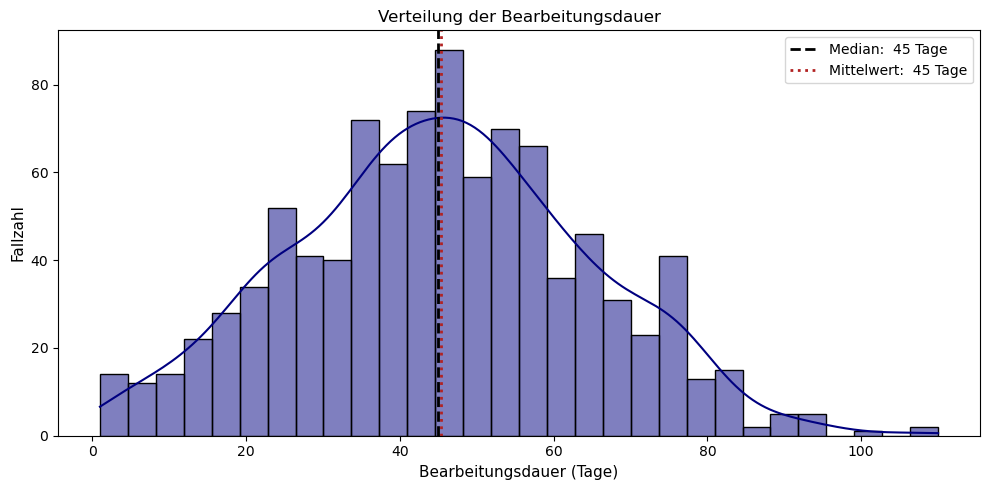

In [47]:
# Histogramm 

from scipy.stats import norm # für Abgleich mit der Normalverteilung


# Histogramm bauen
plt.figure(figsize=(10,5))
sns.histplot(df['bearbeitungsdauer_tage'], kde=True, bins=30, color='navy')


# Vertikale Linie mit Median & Mean
median_bearbeitungszeit = df['bearbeitungsdauer_tage'].median()
mean_bearbeitungszeit = df['bearbeitungsdauer_tage'].mean() 
plt.axvline(median_bearbeitungszeit, color='black', linestyle='--', linewidth=2, label=f"Median: {median_bearbeitungszeit: .0f} Tage")
plt.axvline(mean_bearbeitungszeit, color='firebrick', linestyle=':', linewidth=2, label= f"Mittelwert: {mean_bearbeitungszeit: .0f} Tage")

# Beschriftungen & Format
plt.title("Verteilung der Bearbeitungsdauer") 
plt.xlabel("Bearbeitungsdauer (Tage)", fontsize=11)
plt.ylabel("Fallzahl", fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()


Nach der Entfernung der Ausreißer stellt dieses Histogramm die bereinigte Verteilung der Bearbeitungsdauer dar. Die Daten häufen sich symmetrisch um das Zentrum ($\mu \approx 45$, Median $\approx 45$). Eine extreme Schiefe liegt nicht vor. Die Grafik illustriert die Prozessrealität der Anträge bei der DRV. 

# 4.0 Regression
Der Datensatz besteht aus nominalen Merkmalen (Region, Antragsart, Status) und der metrischen Variable Alter sowie der zu erklärenden Varibale der Bearbeitungsdauer. Daher wird der Einfluss aller Faktoren mithilfe einer multiplen linearen Regression mit Dummy-Codierung berechnet. Daran anschließend folgt die Residuenanalyse. 

## 4.1 Dummy-Codierung
Um eine Multikollinearität bei der Dummy-Codierung zu vermeiden, wähle ich nach k-1 jeweils eine Referenzkategorie aus. Ich orientiere mich hier an Best Practices und wähle die Referenzkategorie danach, welche Ausprägung die größte Fallzahl hat, um statistische Stabilität zu garantieren.  
Wir beginnen nun mit der Spalte 'region'.  

In [38]:
# Dummy-Codierung der Variablen Region & Antragsart
# 1. Region
#Ermittlung der Stadt mit höchster Fallzahl
print(f"Höchste Fallzahl desc: {df['region'].value_counts()}")
print(f"Reihenfolge der Werte: {df['region'].unique()}")

Höchste Fallzahl desc: region
Kassel       203
Frankfurt    201
Wiesbaden    197
Gießen       195
Darmstadt    172
Name: count, dtype: int64
Reihenfolge der Werte: ['Gießen' 'Darmstadt' 'Wiesbaden' 'Frankfurt' 'Kassel']


Kassel hat die höchste Fallzahl, steht allerdings an letzter Stelle. Mit der Funktion pd.get_dummies() ist es möglich eine Kategorie als Referenzkategorie "fallen zu lassen", allerdings ist dies nur mit dem ersten Wert der Liste möglich. Daher ist eine Operation an der Reihenfolge der Werte notwendig, damit wir Kassel an erste Stelle setzen und als Referenzkategorie festlegen können.

In [39]:
# Veränderung der Reihenfolge der Werte in Region
df['region'] = pd.Categorical(df['region'], categories = ['Kassel', 'Frankfurt', 'Wiesbaden', 'Gießen', 'Darmstadt']) 

# Kontrolle
print(f"Neue Reihenfolge: {df['region'].cat.categories}")


Neue Reihenfolge: Index(['Kassel', 'Frankfurt', 'Wiesbaden', 'Gießen', 'Darmstadt'], dtype='object')


Wir wenden nun das gleiche Prozedere für 'antragsart' und 'status' an und ermitteln die Werte mit der höchsten Fallzahl.

In [40]:
# Kontrolle der Reihenfolge in Antragsart
print(f"Höchste Fallzahl desc: {df['antragsart'].value_counts()}")

# Kontrolle der Reihenfolge Status
print(f"Höchste Fallzahl desc:{df['status'].value_counts()}")

Höchste Fallzahl desc: antragsart
Altersrente               592
Erwerbsminderungsrente    228
Reha-Maßnahme             148
Name: count, dtype: int64
Höchste Fallzahl desc:status
Bewilligt    739
Abgelehnt    229
Name: count, dtype: int64


In [ ]:
# Änderung der Reihenfolge für Antragsart
df['antragsart'] = pd.Categorical(df['antragsart'], categories= ['Altersrente', 'Erwerbsminderungsrente', 'Reha-Maßnahme'])

# Änderung der Reihenfolge für Status
df['status'] = pd.Categorical(df['status'], categories = ['Bewilligt', 'Abgelehnt'])

Da nun die Werte mit höchster Fallzahl bei allen kategorialen Variable an erster Stelle gesetzt wurde, können wir nun in einem Schritt die Dummy-Codierung vornehmen und die Referenzkategorie festlegen bzw. "fallen lassen".

In [42]:
# Erstellung Dummy-Variablen bzw. des Dummy-Dataframes
df_model = pd.get_dummies(df, columns= ['region', 'antragsart', 'status'], drop_first=True, dtype=int)
df_model.head()

,vorgangs_id,alter_jahre,bearbeitungsdauer_tage,region_Frankfurt,region_Wiesbaden,region_Gießen,region_Darmstadt,antragsart_Erwerbsminderungsrente,antragsart_Reha-Maßnahme,status_Abgelehnt
0,10000,35,73,0,0,1,0,0,0,0
1,10001,59,58,0,0,0,1,0,1,1
2,10002,44,57,0,1,0,0,1,0,0
3,10003,57,22,1,0,0,0,0,0,0
4,10004,58,78,0,1,0,0,0,0,0


## 4.2 Variablendefinition
Als Vorbereitung der Regression wird in diesem Schritt die Bearbeitungsdauer als Zielvariable (Y) und Alter (metrische Variable) sowie Region, Status und Antragsart (Dummy-Variablen) als die erklärenden Prädikatoren zugeordnet.

In [43]:
import statsmodels.api as sm 

# Definition Zielvariable
y = df_model['bearbeitungsdauer_tage']

# Auswahl der Prädikatoren
X = df_model.drop(columns= ['bearbeitungsdauer_tage', 'vorgangs_id'])

# Intercept einfügen
X = sm.add_constant(X)

print("Modell wurde vorbereitet.")

Modell wurde vorbereitet.


## 4.3 Modell Output
Die Regressionsgerade wird nach der Methode der Kleinsten Quadrate (OLS) berechnet und die Regressionskoeffizienten ($beta$) geschätzt. 

In [44]:
# Modell Berechnung
model = sm.OLS(y, X).fit()
print(model.summary())

                              OLS Regression Results                              
Dep. Variable:     bearbeitungsdauer_tage   R-squared:                       0.011
Model:                                OLS   Adj. R-squared:                  0.003
Method:                     Least Squares   F-statistic:                     1.342
Date:                    Mon, 02 Nov 2026   Prob (F-statistic):              0.219
Time:                            14:01:29   Log-Likelihood:                -4228.9
No. Observations:                     968   AIC:                             8476.
Df Residuals:                         959   BIC:                             8520.
Df Model:                               8                                         
Covariance Type:                nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------

**Analyse des Outputs**:  
1.) Das Bestimmtheitsmaß adj. R² zeigt uns, dass das Modell mit den Variablen (Region, Antragsart, Status, Alter) uns lediglich 0,3% der Varianz in der Bearbeitungsdauer erklärt.  

2.) Der hohe p-Wert (0,219 > 5%) der F-Statistik zeigt uns, dass wir nicht davon ausgehen können, dass die gebündelten Variablen des Modells einen systematischen Einfluss auf die Dauer der Bearbeitungszeit haben.  
 
3.) Der Einfluss der einzelnen Variablen ist bis auf das Alter nicht signifikant. Bei Alter liegt ein Signifikanzniveau von 0,037 vor. Damit haben weder die einzelnen Regionen noch die verschiedenen Antragsarten oder der Bearbeitungsstatus einen signifikanten Einfluss auf die Bearbeitungszeit. Lediglich das Alter hat einen signifikant leichten Einfluss auf die Bearbeitungszeit (mit jedem Jahr steigt die Bearbeitungszeit um ca. 0,13 Tagen) 


## 4.4 Residuen Analyse
Zum Abschluss werden die Residuen auf Muster geprüft (Homoskedatizität) sowie ob sie normalvereilt sind.

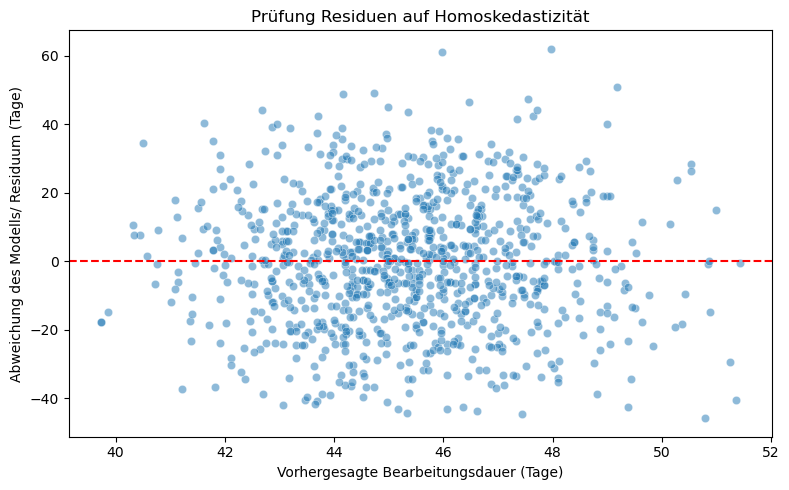

In [45]:
# Werte aus dem Ergebnis ziehen
residuen = model.resid
vorhersagen = model.fittedvalues 

# Scatterplot der Residuen bauen
plt.figure(figsize=(8,5))
sns.scatterplot(x=vorhersagen, y=residuen, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.title('Prüfung Residuen auf Homoskedastizität')
plt.xlabel("Vorhergesagte Bearbeitungsdauer (Tage)")
plt.ylabel("Abweichung des Modells/ Residuum (Tage)")
plt.tight_layout()
plt.show() 

Durch die Grafik erkennen wird, dass die Residuen in der Punktwolke gleichmäßig um die Nulllinie streuen und es kein Muster gibt, welches auf einen systematischen Fehler hindeuten würde. Die Varianzhomogenität ist also gegeben und die Schätzer sind nicht verzerrt. 

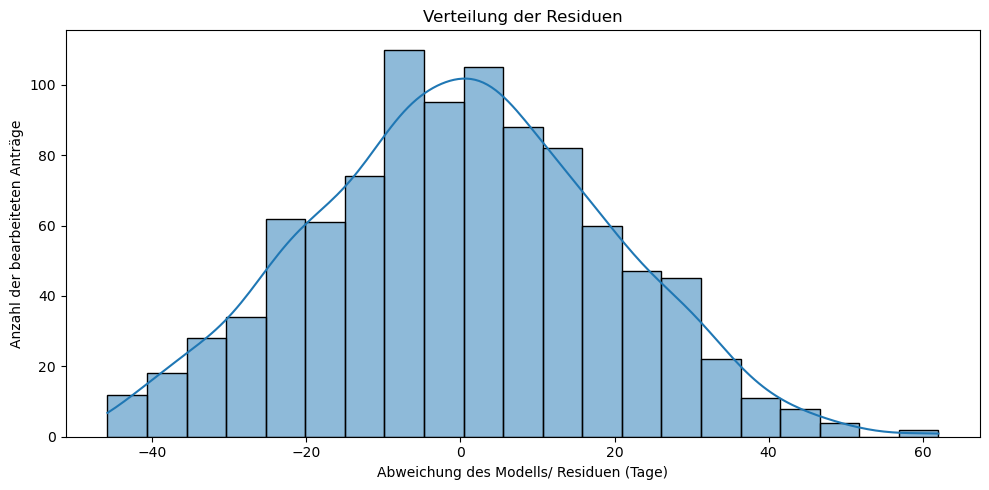

In [46]:
# Prüfung der Residuen auf Normalverteilung
plt.figure(figsize=(10,5))
sns.histplot(residuen, kde=True)
plt.title("Verteilung der Residuen")
plt.xlabel("Abweichung des Modells/ Residuen (Tage)")
plt.ylabel("Anzahl der bearbeiteten Anträge")
plt.tight_layout()

Die Residuen folgen einer Normalverteilung. Damit ist die Verwendung des linearen Regressionsmodells gesichert und die berechneten p-Werte und F-Statistik statistisch belastbar.  
Es kann also abschließend bestätigt werden, dass die Schlussfolgerung einer Gleichbehandlung aller Anträge bei der DRV vorliegt.  

# 5. Management Summary 

## Treiber der Bearbeitungsdauer
Die zentrale Fragestellung des vorliegenden Projektes war die Identifikation von systematischen Einflussfaktoren auf die Bearbeitungszeit von Anträgen. Als mögliche Einflussfaktoren wurden die Antragsart, die regionale Zuständigkeit, der Status und das Alter als demografisches Merkmal untersucht. 

## Ergebnisse 
Durch die multivariate Analyse konnte gezeigt werden, dass weder Region noch Antragsart oder Status die Bearbeitungszeit signifikant beeinflussen und wir hier von einer relativen Gleichbehandlung im Prozess ausgehen können. Das statistische Modell bestätigt, dass es hier keine strukturellen Verzögerungen in der Verwaltung gibt. Als einziger signifikanter Einflussfaktor konnte das Alter identifiziert werden. Das Alter weist einen marginalen Effekt von rund 0,13 Tagen pro Lebensjahr auf. Dieser Umstand lässt sich fachlich damit erklären, dass mit zunehmenden Alter die Nachweislast der Antragssteller zunimmt (komplexere Beschäftigungs- und Krankengeschichten etc.). 

## Handlungsempfehlung
Da die Auswertung eine verlässliche Antragsbearbeitung nachweist, sollten die operativen Abläufe beibehalten werden. Vorschläge zur weiteren Optimierung sind:
1. Implementierung eines automatisierten Datenqualitätsmanagements, um Ausreißer bei der Datenerfassung bereits abzufangen.
2. Gezielte Überprüfung des Zusammenhangs zwischen Alter, Nachweislast und Bearbeitungsdauer.  

## Disclaimer
In dem vorliegenden Projekt wurde mit einem synthetisch generierten Datensatz gearbeitet. Sämtliche Zahlenergebnisse, Grafiken und Auswertungen sind als fiktive Ergebnisse zu betrachten und beanspruchen keinerlei Repräsentativität für die tatsächliche Bearbeitungspraxis der DRV Hessen. Der Fokus des Projekts liegt ausschließlich auf **der Demonstration eines methodisch sauberen Workflows** und seiner einzelnen Schritte.